# 2. Análise Descritiva — Panorama do Trabalho Remoto no Brasil (Mai–Nov/2020)

Neste notebook exploramos a evolução e a distribuição do trabalho remoto efetivo no Brasil entre maio e novembro de 2020 utilizando os pesos amostrais calibrados (`peso = V1032`) da PNAD Covid-19.

A análise segue o fio condutor econômico do estudo:
1. **Dinâmica agregada**: redução dos afastamentos por distanciamento social vs. persistência de um núcleo de trabalhadores remotos;
2. **Desigualdades individuais**: gênero, cor/raça e faixa etária;
3. **O papel central da escolaridade**: concentração no ensino superior e taxa interna de adesão ao teletrabalho;
4. **Dimensão territorial**: concentração no Sudeste e correlação espacial com ensino superior nas 27 UFs;
5. **Estrutura ocupacional**: iniciativa (privada vs. pública), formalidade e setor de atividade;
6. **Ponte para a econometria**: por que a escolaridade ajuda a explicar — mas também pode mascarar — diferenciais aparentes de gênero e setor.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    ESCOLARIDADE_ORDER,
    FAIXA_ETARIA_DESC_ORDER,
    MES_LABELS,
    MES_ORDER,
    PALETTE,
    PROCESSED_DATA_PATH,
    SETOR_ORDER,
)
from src.data_processing import load_analytic_dataset
from src.descriptive import (
    panorama_ocupacao_mensal,
    resumo_por_regiao,
    resumo_por_uf,
    weighted_remote_rate,
    weighted_table,
)
from src.visualization import (
    add_title_and_source,
    format_ptbr_number,
    plot_dual_state_maps,
    save_figure,
    set_portfolio_style,
    style_percent_axis,
)

set_portfolio_style()
df = load_analytic_dataset(PROCESSED_DATA_PATH)
ocup = df[df["ocupado"]].copy()
ocup_nao_afast = df[df["ocupado_nao_afastado"]].copy()
remotos = df[df["trabalho_remoto"] == 1].copy()

print(f"Base carregada: {len(df):,} registros | Ocupados: {len(ocup):,} | Remotos: {len(remotos):,}")


Base carregada: 2,650,459 registros | Ocupados: 1,069,441 | Remotos: 83,799


## 2.1 Panorama do Mercado de Trabalho e Trabalho Remoto (Mai–Nov/2020)

Entre maio e novembro de 2020, o contingente de trabalhadores ocupados aumentou de **86,74 milhões** para **88,95 milhões**, enquanto o número de pessoas afastadas devido ao distanciamento social caiu drasticamente de **16,23 milhões** para **3,97 milhões** (−75,5%).

Em contraste, o trabalho remoto apresentou maior resiliência: partiu de **8,71 milhões** em maio e encerrou novembro em **7,33 milhões** (8,2% do total de ocupados e 8,9% dos ocupados não afastados), sinalizando transição parcial para regimes remotos ou híbridos estruturais.


mes_label,mai/2020,jun/2020,jul/2020,ago/2020,set/2020,out/2020,nov/2020,Proporção nov/2020 (%)
Pessoas ocupadas (total),86743.7,86444.4,86859.6,87636.7,87982.9,88686.3,88949.0,100.0
Ocupadas não afastadas,66948.9,70297.9,73427.2,77277.3,79439.0,81376.6,82147.4,92.4
Em trabalho remoto,8709.3,8693.8,8402.8,8375.8,8073.4,7596.0,7330.1,8.2
Em trabalho presencial,58239.6,61604.0,65024.4,68901.5,71365.6,73780.6,74817.3,84.1
Ocupadas e afastadas,19794.8,16146.6,13432.4,10359.3,8543.9,7309.7,6801.6,7.6
Afastadas por distanciamento social,16225.6,12843.7,10007.0,7343.0,5693.0,4489.4,3972.3,58.4
Afastadas por outras razões,3569.1,3302.9,3425.4,3016.3,2850.9,2820.4,2829.3,41.6


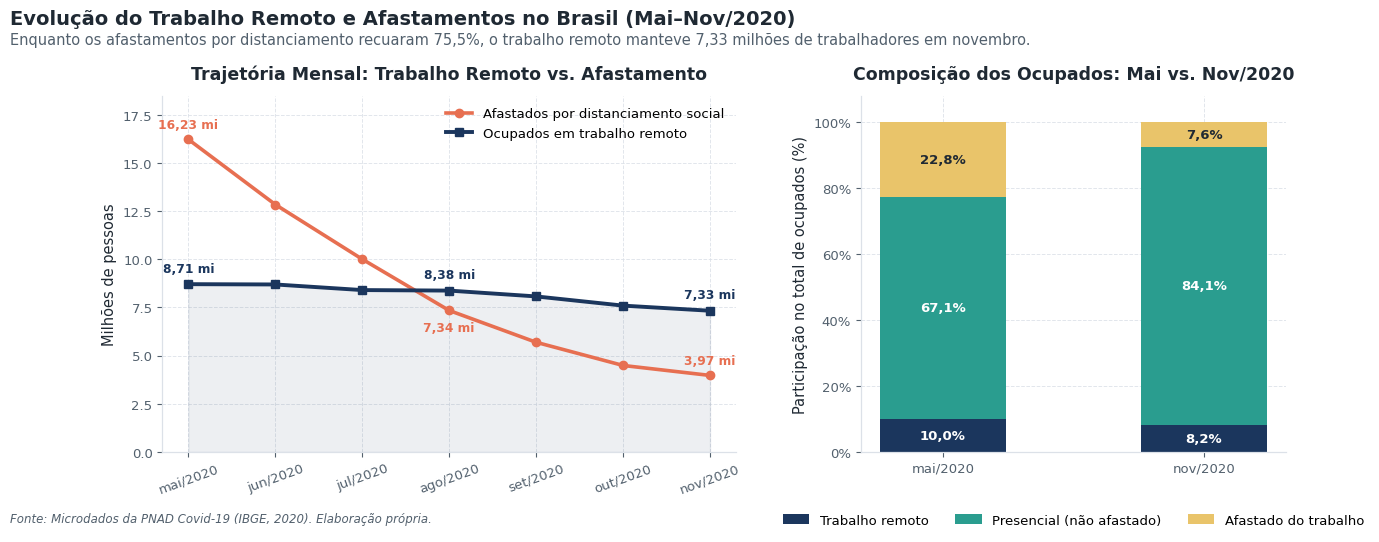

In [2]:
panorama = panorama_ocupacao_mensal(df)
display(panorama.round(1))

# Figura 01: Evolução temporal e composição em maio vs novembro
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14.5, 5.4), gridspec_kw={"width_ratios": [1.35, 1.0]})
fig.subplots_adjust(top=0.80, bottom=0.14, wspace=0.25)

meses = list(panorama.columns[:-1])
rem_mi = panorama.loc["    Em trabalho remoto", meses].to_numpy(dtype=float) / 1e3
afast_dist_mi = panorama.loc["    Afastadas por distanciamento social", meses].to_numpy(dtype=float) / 1e3

ax1.plot(meses, afast_dist_mi, marker="o", lw=2.6, color=PALETTE["coral"], label="Afastados por distanciamento social")
ax1.plot(meses, rem_mi, marker="s", lw=2.8, color=PALETTE["navy"], label="Ocupados em trabalho remoto")
ax1.fill_between(meses, rem_mi, color=PALETTE["navy"], alpha=0.08)

for i, (m, r_val, a_val) in enumerate(zip(meses, rem_mi, afast_dist_mi)):
    if i in (0, 3, 6):
        ax1.annotate(f"{format_ptbr_number(r_val, 2)} mi", (m, r_val), xytext=(0, 9), textcoords="offset points",
                     ha="center", fontsize=8.8, fontweight="bold", color=PALETTE["navy"])
        a_offset = (0, -15) if i == 3 else (0, 8)
        ax1.annotate(f"{format_ptbr_number(a_val, 2)} mi", (m, a_val), xytext=a_offset, textcoords="offset points",
                     ha="center", fontsize=8.8, fontweight="bold", color=PALETTE["coral"])

ax1.set_title("Trajetória Mensal: Trabalho Remoto vs. Afastamento", pad=12)
ax1.set_ylabel("Milhões de pessoas")
ax1.set_ylim(0, 18.5)
ax1.legend(loc="upper right")
ax1.tick_params(axis="x", rotation=20)

# Painel direito: composição dos ocupados em mai/2020 e nov/2020
comp_cols = ["mai/2020", "nov/2020"]
cats_comp = [
    ("    Em trabalho remoto", "Trabalho remoto", PALETTE["navy"]),
    ("    Em trabalho presencial", "Presencial (não afastado)", PALETTE["teal"]),
    ("  Ocupadas e afastadas", "Afastado do trabalho", PALETTE["amber"]),
]
bottom = np.zeros(2)
for row_key, label, color in cats_comp:
    vals = np.array([
        panorama.loc[row_key, m] / panorama.loc["Pessoas ocupadas (total)", m] * 100.0
        for m in comp_cols
    ])
    bars = ax2.bar(comp_cols, vals, bottom=bottom, width=0.48, label=label, color=color)
    for bar, v, b in zip(bars, vals, bottom):
        txt_col = "#FFFFFF" if color != PALETTE["amber"] else PALETTE["dark_text"]
        ax2.text(bar.get_x() + bar.get_width() / 2, b + v / 2, f"{format_ptbr_number(v, 1)}%",
                 ha="center", va="center", fontsize=9.5, fontweight="bold", color=txt_col)
    bottom += vals

ax2.set_title("Composição dos Ocupados: Mai vs. Nov/2020", pad=12)
ax2.set_ylabel("Participação no total de ocupados (%)")
ax2.set_ylim(0, 108)
style_percent_axis(ax2, axis="y")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3)

add_title_and_source(
    fig,
    "Evolução do Trabalho Remoto e Afastamentos no Brasil (Mai–Nov/2020)",
    "Enquanto os afastamentos por distanciamento recuaram 75,5%, o trabalho remoto manteve 7,33 milhões de trabalhadores em novembro.",
    title_y=0.96,
    subtitle_y=0.895,
    source_y=0.01,
)
save_figure(fig, "01_evolucao_ocupados_remoto.png")
plt.show()


## 2.2 Características Individuais: Gênero, Cor/Raça e Faixa Etária

Analisando o perfil demográfico do trabalho remoto:
- **Gênero**: embora sejam minoria entre os ocupados totais, as **mulheres representam 57,8%** dos trabalhadores remotos em novembro/2020 (4,24 milhões contra 3,09 milhões de homens), além de terem apresentado saída menos acentuada entre maio e novembro (−9,2% entre mulheres vs. −23,5% entre homens).
- **Cor/Raça**: pessoas **Brancas e Amarelas** respondem por cerca de dois terços dos postos remotos em ambos os sexos (**69%** entre homens e **64%** entre mulheres em novembro/2020), com incidência interna de trabalho remoto quase duas vezes superior à de Pretos, Pardos e Indígenas.
- **Faixa Etária**: concentração predominante entre adultos de **30 a 49 anos** (~57% dos remotos em novembro).


Trabalhadores remotos por gênero (milhares):


mes_label,mai/2020,jun/2020,jul/2020,ago/2020,set/2020,out/2020,nov/2020,Proporção nov/2020 (%)
genero,,,,,,,,
Homem,4039.7,3868.3,3726.0,3614.4,3471.0,3273.1,3090.5,42.2
Mulher,4669.6,4825.5,4676.8,4761.4,4602.5,4322.9,4239.6,57.8



Trabalhadores remotos por gênero e raça (milhares):


mes_label                          mai/2020  jun/2020  jul/2020  ago/2020  \
genero raca                                                                 
Homem  Branca e Amarela              2703.3    2564.8    2509.2    2428.7   
       Pretos, Pardos e Indígenas    1335.2    1303.3    1216.8    1185.7   
Mulher Branca e Amarela              3000.1    3117.2    3029.4    3056.7   
       Pretos, Pardos e Indígenas    1669.6    1708.3    1647.1    1704.1   

mes_label                          set/2020  out/2020  nov/2020  
genero raca                                                      
Homem  Branca e Amarela              2371.3    2237.4    2117.2  
       Pretos, Pardos e Indígenas    1099.5    1035.7     973.3  
Mulher Branca e Amarela              2939.4    2730.5    2695.2  
       Pretos, Pardos e Indígenas    1663.1    1592.4    1544.4

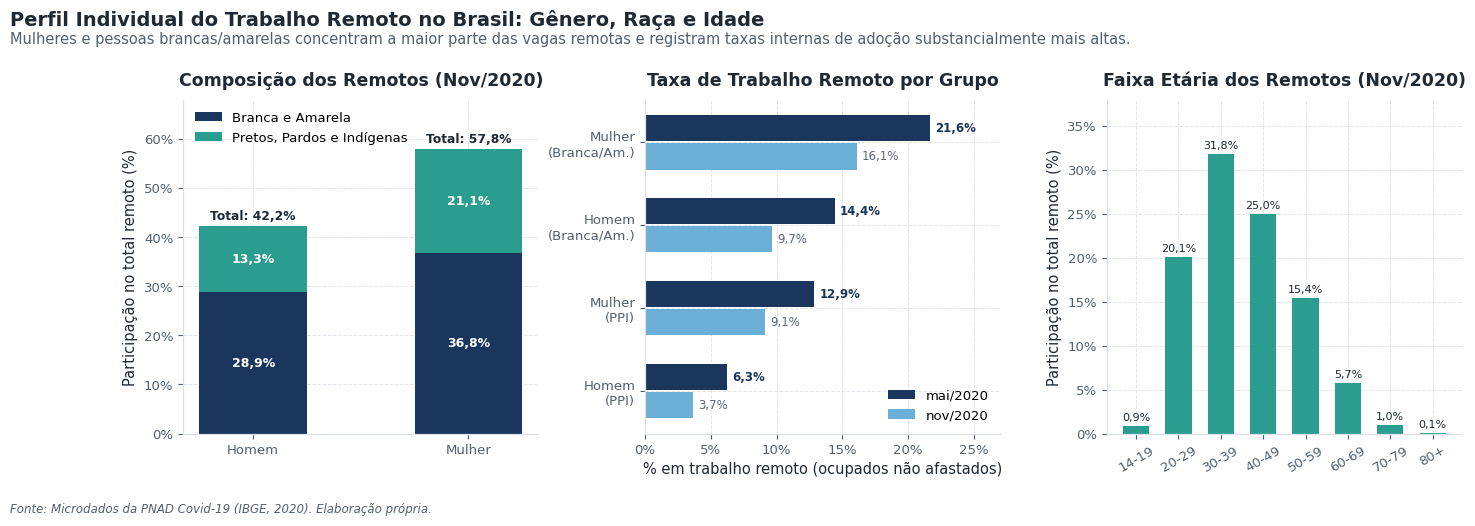

In [3]:
tab_genero = weighted_table(remotos, "genero", "mes_label", scale=1e3)
tab_genero["Proporção nov/2020 (%)"] = tab_genero["nov/2020"] / tab_genero["nov/2020"].sum() * 100.0
print("Trabalhadores remotos por gênero (milhares):")
display(tab_genero.round(1))

tab_gen_raca = weighted_table(remotos.dropna(subset=["raca"]), ["genero", "raca"], "mes_label", scale=1e3)
print("\nTrabalhadores remotos por gênero e raça (milhares):")
display(tab_gen_raca.round(1))

# Taxa interna de trabalho remoto (entre ocupados não afastados) por gênero e raça em Mai e Nov
rates_gr = []
for mes_num in (5, 11):
    sub_m = ocup_nao_afast[(ocup_nao_afast["mes"] == mes_num) & ocup_nao_afast["raca"].notna()]
    r_df = weighted_remote_rate(sub_m, ["genero", "raca"]).reset_index()
    r_df["mes"] = MES_LABELS[mes_num]
    rates_gr.append(r_df)
rates_gr_df = pd.concat(rates_gr, ignore_index=True)

# Figura 02: Perfil Demográfico (Gênero x Raça composição, Taxa interna e Faixa etária)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 5.3))
fig.subplots_adjust(top=0.79, bottom=0.16, wspace=0.30)

# Painel A: Participação no contingente remoto por Gênero x Raça (nov/2020)
nov_rem_gr = weighted_table(
    remotos[(remotos["mes"] == 11) & remotos["raca"].notna()],
    "genero",
    "raca",
    normalize="all",
)
x_pos = np.arange(len(nov_rem_gr.index))
w_bar = 0.5
b1 = ax1.bar(x_pos, nov_rem_gr["Branca e Amarela"], width=w_bar, color=PALETTE["navy"], label="Branca e Amarela")
b2 = ax1.bar(x_pos, nov_rem_gr["Pretos, Pardos e Indígenas"], bottom=nov_rem_gr["Branca e Amarela"],
             width=w_bar, color=PALETTE["teal"], label="Pretos, Pardos e Indígenas")
for i, g in enumerate(nov_rem_gr.index):
    v1 = nov_rem_gr.loc[g, "Branca e Amarela"]
    v2 = nov_rem_gr.loc[g, "Pretos, Pardos e Indígenas"]
    ax1.text(i, v1 / 2, f"{format_ptbr_number(v1, 1)}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    ax1.text(i, v1 + v2 / 2, f"{format_ptbr_number(v2, 1)}%", ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    ax1.text(i, v1 + v2 + 1.5, f"Total: {format_ptbr_number(v1 + v2, 1)}%", ha="center", fontsize=8.8, fontweight="bold", color=PALETTE["dark_text"])
ax1.set_xticks(x_pos)
ax1.set_xticklabels(nov_rem_gr.index)
ax1.set_ylim(0, 68)
style_percent_axis(ax1, axis="y")
ax1.set_title("Composição dos Remotos (Nov/2020)", pad=10)
ax1.set_ylabel("Participação no total remoto (%)")
ax1.legend(loc="upper left")

# Painel B: Taxa interna de trabalho remoto (Mai vs Nov) por Gênero x Raça
rates_gr_df["grupo"] = rates_gr_df["genero"].astype(str) + "\n(" + rates_gr_df["raca"].astype(str).map(
    {"Branca e Amarela": "Branca/Am.", "Pretos, Pardos e Indígenas": "PPI"}
) + ")"
piv_rate = rates_gr_df.pivot(index="grupo", columns="mes", values="taxa_remoto_pct")[["mai/2020", "nov/2020"]]
piv_rate = piv_rate.sort_values("mai/2020", ascending=True)
y_idx = np.arange(len(piv_rate))
ax2.barh(y_idx + 0.17, piv_rate["mai/2020"], height=0.32, color=PALETTE["navy"], label="mai/2020")
ax2.barh(y_idx - 0.17, piv_rate["nov/2020"], height=0.32, color=PALETTE["blue_light"], label="nov/2020")
for yi, (_, row) in enumerate(piv_rate.iterrows()):
    ax2.text(row["mai/2020"] + 0.4, yi + 0.17, f"{format_ptbr_number(row['mai/2020'], 1)}%", va="center", fontsize=8.5, color=PALETTE["navy"], fontweight="bold")
    ax2.text(row["nov/2020"] + 0.4, yi - 0.17, f"{format_ptbr_number(row['nov/2020'], 1)}%", va="center", fontsize=8.5, color=PALETTE["slate"])
ax2.set_yticks(y_idx)
ax2.set_yticklabels(piv_rate.index)
ax2.set_xlim(0, 27)
style_percent_axis(ax2, axis="x")
ax2.set_title("Taxa de Trabalho Remoto por Grupo", pad=10)
ax2.set_xlabel("% em trabalho remoto (ocupados não afastados)")
ax2.legend(loc="lower right")

# Painel C: Distribuição por faixa etária (nov/2020)
nov_idade = weighted_table(
    remotos[(remotos["mes"] == 11) & remotos["faixa_etaria_desc"].notna()],
    "faixa_etaria_desc",
    normalize="all",
).reindex(FAIXA_ETARIA_DESC_ORDER)
bars_age = ax3.bar(nov_idade.index.astype(str), nov_idade["total"], color=PALETTE["teal"], width=0.62)
for bar in bars_age:
    h = bar.get_height()
    if h >= 0.05:
        ax3.text(bar.get_x() + bar.get_width() / 2, h + 0.6, f"{format_ptbr_number(h, 1)}%", ha="center", fontsize=8.0, color=PALETTE["dark_text"])
ax3.set_ylim(0, 38)
style_percent_axis(ax3, axis="y")
ax3.set_title("Faixa Etária dos Remotos (Nov/2020)", pad=10)
ax3.set_ylabel("Participação no total remoto (%)")
ax3.tick_params(axis="x", rotation=30)

add_title_and_source(
    fig,
    "Perfil Individual do Trabalho Remoto no Brasil: Gênero, Raça e Idade",
    "Mulheres e pessoas brancas/amarelas concentram a maior parte das vagas remotas e registram taxas internas de adoção substancialmente mais altas.",
    title_y=0.96,
    subtitle_y=0.895,
    source_y=0.01,
)
save_figure(fig, "02_perfil_genero_raca_idade.png")
plt.show()


## 2.3 O Papel Central da Escolaridade

A escolaridade emerge como o principal divisor estrutural do trabalho remoto no Brasil:
- Em novembro de 2020, **76,0% de todos os trabalhadores remotos** possuíam **ensino superior completo (50,5%)** ou **pós-graduação, mestrado ou doutorado (25,4%)**. Somando o superior incompleto (11,2%), **87,2%** dos trabalhadores em home office tinham ao menos ingresso no ensino superior.
- Mais expressivo ainda é o salto na **taxa interna de adesão** (percentual de ocupados não afastados que trabalham remotamente dentro de cada nível educacional): abaixo do ensino médio completo a taxa fica abaixo de 2%, sobe para 5,0% no médio completo, salta para **33,7% em maio (24,9% em novembro)** com superior completo e atinge **52,4% em maio (40,6% em novembro)** entre pós-graduados!


mes_label,mai/2020,jun/2020,jul/2020,ago/2020,set/2020,out/2020,nov/2020,Proporção nov/2020 (%)
escolaridade,,,,,,,,
Sem instrução,2.8,1.3,1.4,2.9,1.7,1.5,1.4,0.0
Fundamental incompleto,67.0,49.9,61.5,64.6,47.4,50.3,43.6,0.6
Fundamental completo,67.6,58.8,59.8,55.4,47.3,47.2,40.3,0.5
Médio incompleto,98.5,89.0,76.4,83.1,74.8,72.9,77.1,1.1
Médio completo,1123.6,1104.9,1039.9,990.8,859.6,822.1,775.9,10.6
Superior incompleto,1009.9,987.2,984.9,926.2,901.9,831.0,822.6,11.2
Superior completo,4339.9,4318.0,4188.2,4201.2,4065.6,3837.0,3705.2,50.5
"Pós-graduação, mestrado ou doutorado",2000.0,2084.7,1990.7,2051.7,2075.1,1934.0,1863.9,25.4


Participação de Superior Completo ou Pós entre remotos (nov/2020): 76.0%


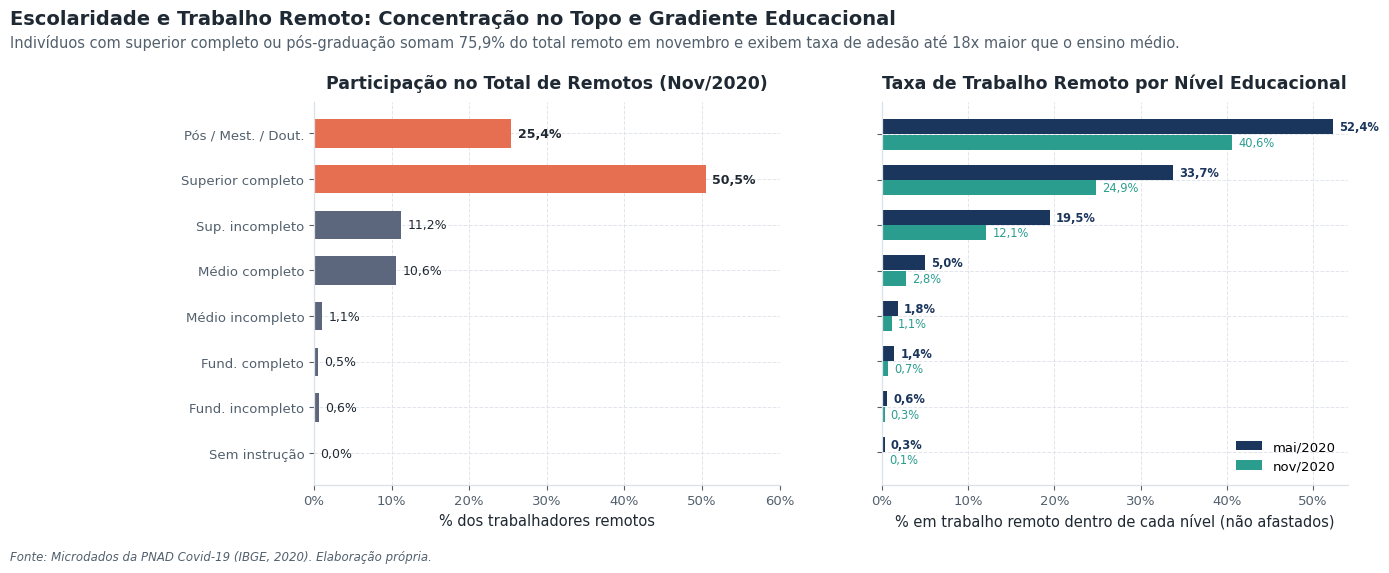

In [4]:
tab_esc_rem = weighted_table(remotos, "escolaridade", "mes_label", scale=1e3).reindex(ESCOLARIDADE_ORDER)
tab_esc_rem["Proporção nov/2020 (%)"] = tab_esc_rem["nov/2020"] / tab_esc_rem["nov/2020"].sum() * 100.0
display(tab_esc_rem.round(1))

sup_nov_share = tab_esc_rem.loc[["Superior completo", "Pós-graduação, mestrado ou doutorado"], "Proporção nov/2020 (%)"].sum()
print(f"Participação de Superior Completo ou Pós entre remotos (nov/2020): {sup_nov_share:.1f}%")

esc_mai = weighted_remote_rate(ocup_nao_afast[ocup_nao_afast["mes"] == 5], "escolaridade").reindex(ESCOLARIDADE_ORDER)
esc_nov = weighted_remote_rate(ocup_nao_afast[ocup_nao_afast["mes"] == 11], "escolaridade").reindex(ESCOLARIDADE_ORDER)

# Figura 03: Composição dos remotos vs Taxa interna por escolaridade
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.2, 5.8))
fig.subplots_adjust(top=0.80, bottom=0.14, left=0.22, wspace=0.22)

short_esc = {
    "Sem instrução": "Sem instrução",
    "Fundamental incompleto": "Fund. incompleto",
    "Fundamental completo": "Fund. completo",
    "Médio incompleto": "Médio incompleto",
    "Médio completo": "Médio completo",
    "Superior incompleto": "Sup. incompleto",
    "Superior completo": "Superior completo",
    "Pós-graduação, mestrado ou doutorado": "Pós / Mest. / Dout.",
}
y_labels = [short_esc[c] for c in ESCOLARIDADE_ORDER]
y_pos = np.arange(len(y_labels))

colors_esc = [
    PALETTE["coral"] if c in ("Superior completo", "Pós-graduação, mestrado ou doutorado") else PALETTE["slate"]
    for c in ESCOLARIDADE_ORDER
]
vals_comp = tab_esc_rem["Proporção nov/2020 (%)"].to_numpy()
ax1.barh(y_pos, vals_comp, color=colors_esc, height=0.62)
for yi, v in enumerate(vals_comp):
    ax1.text(v + 0.8, yi, f"{format_ptbr_number(v, 1)}%", va="center", fontsize=9,
             fontweight="bold" if v > 20 else "normal", color=PALETTE["dark_text"])
ax1.set_yticks(y_pos)
ax1.set_yticklabels(y_labels)
ax1.set_xlim(0, 60)
style_percent_axis(ax1, axis="x")
ax1.set_title("Participação no Total de Remotos (Nov/2020)", pad=10)
ax1.set_xlabel("% dos trabalhadores remotos")

# Painel B: Taxa interna em Mai vs Nov
ax2.barh(y_pos + 0.17, esc_mai["taxa_remoto_pct"], height=0.33, color=PALETTE["navy"], label="mai/2020")
ax2.barh(y_pos - 0.17, esc_nov["taxa_remoto_pct"], height=0.33, color=PALETTE["teal"], label="nov/2020")
for yi, (vm, vn) in enumerate(zip(esc_mai["taxa_remoto_pct"], esc_nov["taxa_remoto_pct"])):
    ax2.text(vm + 0.7, yi + 0.17, f"{format_ptbr_number(vm, 1)}%", va="center", fontsize=8.3, color=PALETTE["navy"], fontweight="bold")
    ax2.text(vn + 0.7, yi - 0.17, f"{format_ptbr_number(vn, 1)}%", va="center", fontsize=8.3, color=PALETTE["teal"])
ax2.set_yticks(y_pos)
ax2.set_yticklabels([])
ax2.set_xlim(0, 54)
style_percent_axis(ax2, axis="x")
ax2.set_title("Taxa de Trabalho Remoto por Nível Educacional", pad=10)
ax2.set_xlabel("% em trabalho remoto dentro de cada nível (não afastados)")
ax2.legend(loc="lower right")

add_title_and_source(
    fig,
    "Escolaridade e Trabalho Remoto: Concentração no Topo e Gradiente Educacional",
    "Indivíduos com superior completo ou pós-graduação somam 75,9% do total remoto em novembro e exibem taxa de adesão até 18x maior que o ensino médio.",
    title_y=0.96,
    subtitle_y=0.895,
    source_y=0.01,
)
save_figure(fig, "03_escolaridade_trabalho_remoto.png")
plt.show()


## 2.4 Desigualdade Regional e por Unidade da Federação

No recorte territorial em novembro de 2020:
- A região **Sudeste concentra 58,3%** de todos os trabalhadores remotos do Brasil (~4,28 milhões), liderada por **São Paulo** (35,3% do contingente nacional), **Rio de Janeiro** (13,1%) e **Minas Gerais** (8,5%).
- Quando medimos a **incidência interna** (percentual dos ocupados totais de cada UF que trabalha remotamente), o **Distrito Federal** lidera com folga (**18,2%** dos ocupados totais e **19,8%** dos não afastados), refletindo tanto o peso da administração pública quanto a maior proporção de ocupados com ensino superior completo (**41,5%**).


Distribuição regional do trabalho remoto (nov/2020):


,regiao,ocupados_mil,remotos_mil,participacao_remoto_pct,taxa_remoto_ocupados_pct,prop_superior_ocupados_pct
0,Sudeste,39449.15,4276.17,58.34,10.84,26.46
1,Nordeste,20627.48,1181.34,16.12,5.73,18.71
2,Sul,14467.23,1074.92,14.66,7.43,24.12
3,Centro-Oeste,7539.77,557.58,7.61,7.40,26.07
4,Norte,6865.33,240.07,3.28,3.50,17.60



Top 10 UFs por participação no total nacional de remotos (nov/2020):


,uf_sigla,uf,regiao,ocupados_mil,remotos_mil,participacao_remoto_pct,taxa_remoto_ocupados_pct,taxa_remoto_nao_afast_pct,prop_superior_ocupados_pct,prop_sem_superior_ocupados_pct
0,SP,São Paulo,Sudeste,21138.06,2585.60,35.27,12.23,13.04,28.81,71.19
1,RJ,Rio de Janeiro,Sudeste,7004.08,959.93,13.10,13.71,15.59,29.89,70.11
2,MG,Minas Gerais,Sudeste,9498.17,624.40,8.52,6.57,7.10,19.81,80.19
3,PR,Paraná,Sul,5445.46,433.98,5.92,7.97,8.47,25.96,74.04
4,RS,Rio Grande do Sul,Sul,5482.36,394.90,5.39,7.20,7.78,21.89,78.11
5,BA,Bahia,Nordeste,5745.16,283.59,3.87,4.94,5.45,17.30,82.70
6,DF,Distrito Federal,Centro-Oeste,1377.18,251.13,3.43,18.23,19.84,41.50,58.50
7,SC,Santa Catarina,Sul,3539.41,246.04,3.36,6.95,7.43,24.72,75.28
8,PE,Pernambuco,Nordeste,3509.48,222.24,3.03,6.33,6.98,21.00,79.00
9,CE,Ceará,Nordeste,3438.41,204.08,2.78,5.94,6.50,19.59,80.41


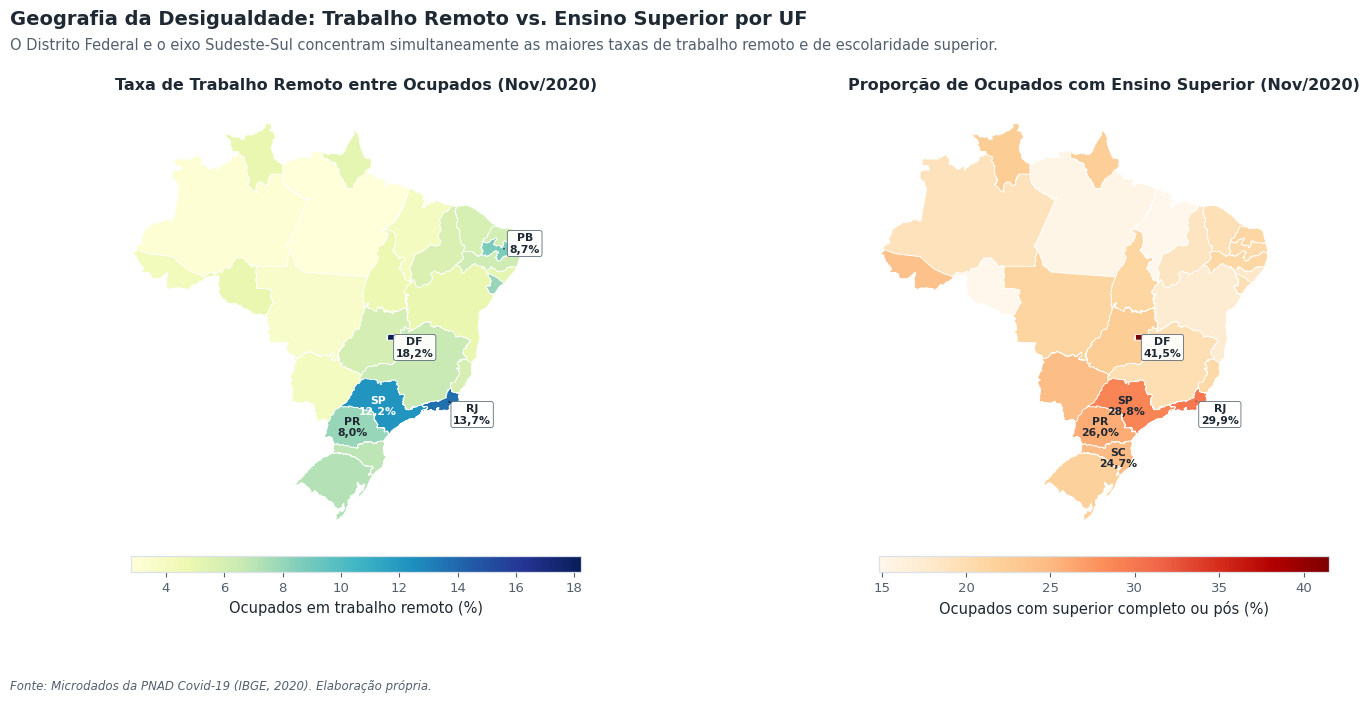

In [5]:
reg_nov = resumo_por_regiao(df, mes=11)
print("Distribuição regional do trabalho remoto (nov/2020):")
display(reg_nov.round(2))

uf_nov = resumo_por_uf(df, mes=11)
print("\nTop 10 UFs por participação no total nacional de remotos (nov/2020):")
display(uf_nov.head(10).round(2))

fig_map = plot_dual_state_maps(
    uf_df=uf_nov,
    left_col="taxa_remoto_ocupados_pct",
    right_col="prop_superior_ocupados_pct",
    left_title="Taxa de Trabalho Remoto entre Ocupados (Nov/2020)",
    right_title="Proporção de Ocupados com Ensino Superior (Nov/2020)",
    left_cbar_label="Ocupados em trabalho remoto (%)",
    right_cbar_label="Ocupados com superior completo ou pós (%)",
    suptitle="Geografia da Desigualdade: Trabalho Remoto vs. Ensino Superior por UF",
    subtitle="O Distrito Federal e o eixo Sudeste-Sul concentram simultaneamente as maiores taxas de trabalho remoto e de escolaridade superior.",
)
save_figure(fig_map, "04_mapa_remoto_e_superior_uf.png")
plt.show()


## 2.5 Perfil Ocupacional: Iniciativa, Formalidade e Setor de Atividade

Entre maio e novembro de 2020, o perfil ocupacional do trabalho remoto revela três traços marcantes:
1. **Iniciativa**: o setor **Privado** lidera em maio (**49,0%** dos remotos), mas perde participação relativa até novembro (**44,0%**), enquanto o setor **Público** avança de **31,9%** para **38,9%** pela maior retenção do regime remoto no funcionalismo.
2. **Formalidade**: o vínculo **Formal** responde por aproximadamente **86%** dos trabalhadores remotos em todo o período (85,7% em maio; 85,9% em novembro).
3. **Setor de Atividade**: o setor de **Serviços** concentra **70,3%** dos remotos em novembro (taxa interna de 14,7%), seguido em incidência pelo **Setor Público** (16,5%), enquanto **Agricultura** (0,6%) e **Comércio** (2,8%) permanecem majoritariamente presenciais.


Participação nos trabalhadores remotos por iniciativa (%):


mes_label,mai/2020,jun/2020,jul/2020,ago/2020,set/2020,out/2020,nov/2020
iniciativa,,,,,,,
Privado,49.0,47.0,46.7,44.8,44.7,44.4,44.0
Público,31.9,34.4,35.0,37.4,37.7,38.4,38.9
Outros,19.1,18.7,18.3,17.9,17.6,17.2,17.0



Taxa interna e participação por setor em nov/2020:


,total_ocupados_mil,remotos_mil,taxa_remoto_pct,participacao_remoto_pct,participacao_ocupados_pct
setor,,,,,
Serviços,35008.42,5155.57,14.73,70.33,43.64
Indústria,15159.18,576.65,3.80,7.87,18.89
Comércio,13838.26,380.73,2.75,5.19,17.25
Setor Público,4625.05,762.21,16.48,10.40,5.76
Agricultura,7213.93,46.69,0.65,0.64,8.99
Outros,4383.80,408.22,9.31,5.57,5.46


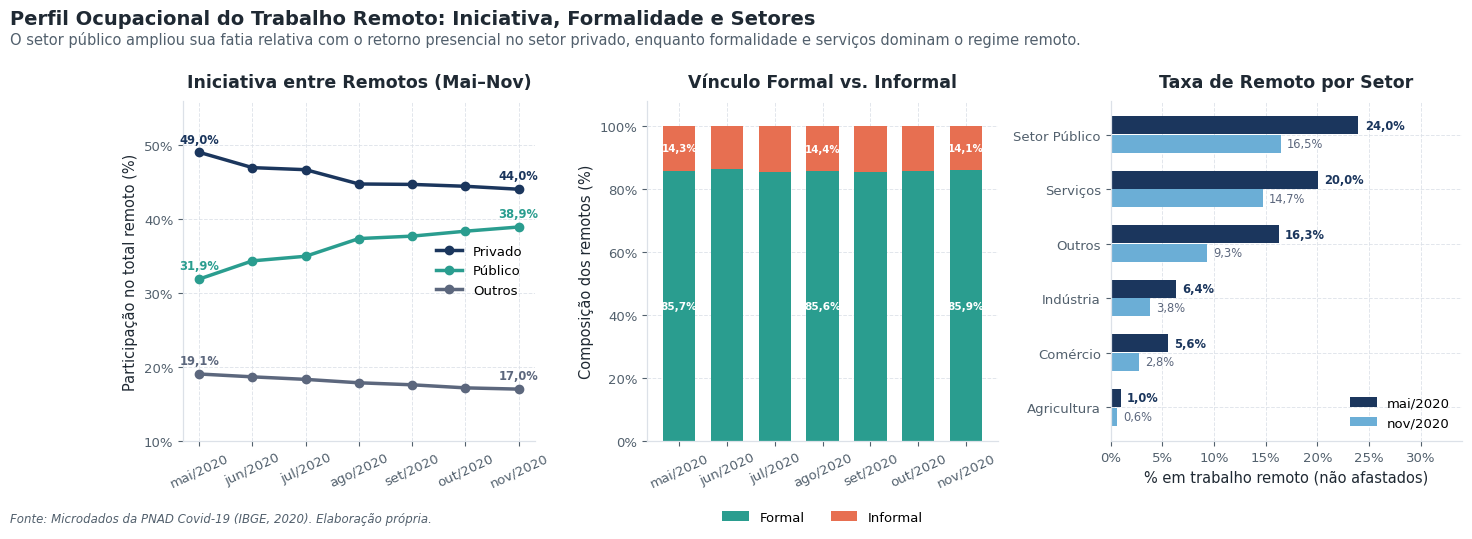

In [6]:
inic_tab = weighted_table(remotos.dropna(subset=["iniciativa"]), "iniciativa", "mes_label", normalize="columns")
form_tab = weighted_table(remotos.dropna(subset=["formalidade"]), "formalidade", "mes_label", normalize="columns")
setor_mai = weighted_remote_rate(ocup_nao_afast[(ocup_nao_afast["mes"] == 5) & ocup_nao_afast["setor"].notna()], "setor")
setor_nov = weighted_remote_rate(ocup_nao_afast[(ocup_nao_afast["mes"] == 11) & ocup_nao_afast["setor"].notna()], "setor")

print("Participação nos trabalhadores remotos por iniciativa (%):")
display(inic_tab.round(1))
print("\nTaxa interna e participação por setor em nov/2020:")
display(setor_nov.round(2))

# Figura 05: Iniciativa, Formalidade e Setor
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 5.4))
fig.subplots_adjust(top=0.79, bottom=0.16, wspace=0.32)

# Painel A: Evolução da participação por iniciativa
colors_inic = {"Privado": PALETTE["navy"], "Público": PALETTE["teal"], "Outros": PALETTE["slate"]}
for cat in ["Privado", "Público", "Outros"]:
    vals = inic_tab.loc[cat, MES_ORDER].to_numpy(dtype=float)
    ax1.plot(MES_ORDER, vals, marker="o", lw=2.5, color=colors_inic[cat], label=cat)
    ax1.annotate(f"{format_ptbr_number(vals[0], 1)}%", (MES_ORDER[0], vals[0]), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.3, color=colors_inic[cat], fontweight="bold")
    ax1.annotate(f"{format_ptbr_number(vals[-1], 1)}%", (MES_ORDER[-1], vals[-1]), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8.3, color=colors_inic[cat], fontweight="bold")
ax1.set_ylim(10, 56)
style_percent_axis(ax1, axis="y")
ax1.set_title("Iniciativa entre Remotos (Mai–Nov)", pad=10)
ax1.set_ylabel("Participação no total remoto (%)")
ax1.tick_params(axis="x", rotation=25)
ax1.legend(loc="center right")

# Painel B: Formal vs Informal ao longo dos meses
x_m = np.arange(len(MES_ORDER))
f_vals = form_tab.loc["Formal", MES_ORDER].to_numpy(dtype=float)
i_vals = form_tab.loc["Informal", MES_ORDER].to_numpy(dtype=float)
ax2.bar(x_m, f_vals, color=PALETTE["teal"], width=0.68, label="Formal")
ax2.bar(x_m, i_vals, bottom=f_vals, color=PALETTE["coral"], width=0.68, label="Informal")
for xi, (fv, iv) in enumerate(zip(f_vals, i_vals)):
    if xi in (0, 3, 6):
        ax2.text(xi, fv / 2, f"{format_ptbr_number(fv, 1)}%", ha="center", va="center", color="white", fontsize=7.6, fontweight="bold")
        ax2.text(xi, fv + iv / 2, f"{format_ptbr_number(iv, 1)}%", ha="center", va="center", color="white", fontsize=7.4, fontweight="bold")
ax2.set_xticks(x_m)
ax2.set_xticklabels(MES_ORDER, rotation=25)
ax2.set_ylim(0, 108)
style_percent_axis(ax2, axis="y")
ax2.set_title("Vínculo Formal vs. Informal", pad=10)
ax2.set_ylabel("Composição dos remotos (%)")
ax2.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)

# Painel C: Taxa interna por setor (Mai vs Nov)
setor_ord = setor_mai.sort_values("taxa_remoto_pct", ascending=True).index.tolist()
y_s = np.arange(len(setor_ord))
ax3.barh(y_s + 0.17, setor_mai.loc[setor_ord, "taxa_remoto_pct"], height=0.33, color=PALETTE["navy"], label="mai/2020")
ax3.barh(y_s - 0.17, setor_nov.loc[setor_ord, "taxa_remoto_pct"], height=0.33, color=PALETTE["blue_light"], label="nov/2020")
for yi, s in enumerate(setor_ord):
    vm = setor_mai.loc[s, "taxa_remoto_pct"]
    vn = setor_nov.loc[s, "taxa_remoto_pct"]
    ax3.text(vm + 0.6, yi + 0.17, f"{format_ptbr_number(vm, 1)}%", va="center", fontsize=8.3, color=PALETTE["navy"], fontweight="bold")
    ax3.text(vn + 0.6, yi - 0.17, f"{format_ptbr_number(vn, 1)}%", va="center", fontsize=8.3, color=PALETTE["slate"])
ax3.set_yticks(y_s)
ax3.set_yticklabels(setor_ord)
ax3.set_xlim(0, 34)
style_percent_axis(ax3, axis="x")
ax3.set_title("Taxa de Remoto por Setor", pad=10)
ax3.set_xlabel("% em trabalho remoto (não afastados)")
ax3.legend(loc="lower right")

add_title_and_source(
    fig,
    "Perfil Ocupacional do Trabalho Remoto: Iniciativa, Formalidade e Setores",
    "O setor público ampliou sua fatia relativa com o retorno presencial no setor privado, enquanto formalidade e serviços dominam o regime remoto.",
    title_y=0.96,
    subtitle_y=0.895,
    source_y=0.01,
)
save_figure(fig, "05_ocupacao_iniciativa_formalidade_setor.png")
plt.show()


## 2.6 Cruzamentos por Escolaridade: A Ponte para a Modelagem Logit

Por que controlar escolaridade e demais atributos simultaneamente — e testar **termos de interação** com `ensino_superior`?

1. Entre as **mulheres ocupadas**, a proporção com ensino superior completo ou pós-graduação é substancialmente maior do que entre os homens. Parte da vantagem feminina observada na análise bruta pode decorrer dessa composição educacional.
2. Entre os ocupados com ensino superior completo ou pós, **mais de 60%** trabalham no setor de **Serviços**, seguido pelo **Setor Público**, exatamente os setores com maior aderência ao trabalho remoto.

No próximo notebook (`03_modelagem_logit.ipynb`), isolaremos os efeitos parciais de cada variável e mediremos como a presença de ensino superior modifica as probabilidades de trabalho remoto dentro de cada subgrupo.


Distribuição educacional dos ocupados por gênero (%, nov/2020):


genero,Homem,Mulher
escolaridade,,
Sem instrução,1.8,0.8
Fundamental incompleto,20.8,12.8
Fundamental completo,7.8,6.0
Médio incompleto,9.7,6.8
Médio completo,34.3,33.5
Superior incompleto,7.4,9.3
Superior completo,14.2,23.3
"Pós-graduação, mestrado ou doutorado",4.1,7.5



Distribuição setorial segundo presença de ensino superior (%, nov/2020):


ensino_superior,Sem superior completo,Superior completo ou pós
setor,,
Serviços,38.6,61.3
Indústria,21.5,9.9
Comércio,19.2,9.8
Setor Público,4.2,11.7
Agricultura,11.0,1.8
Outros,5.4,5.4


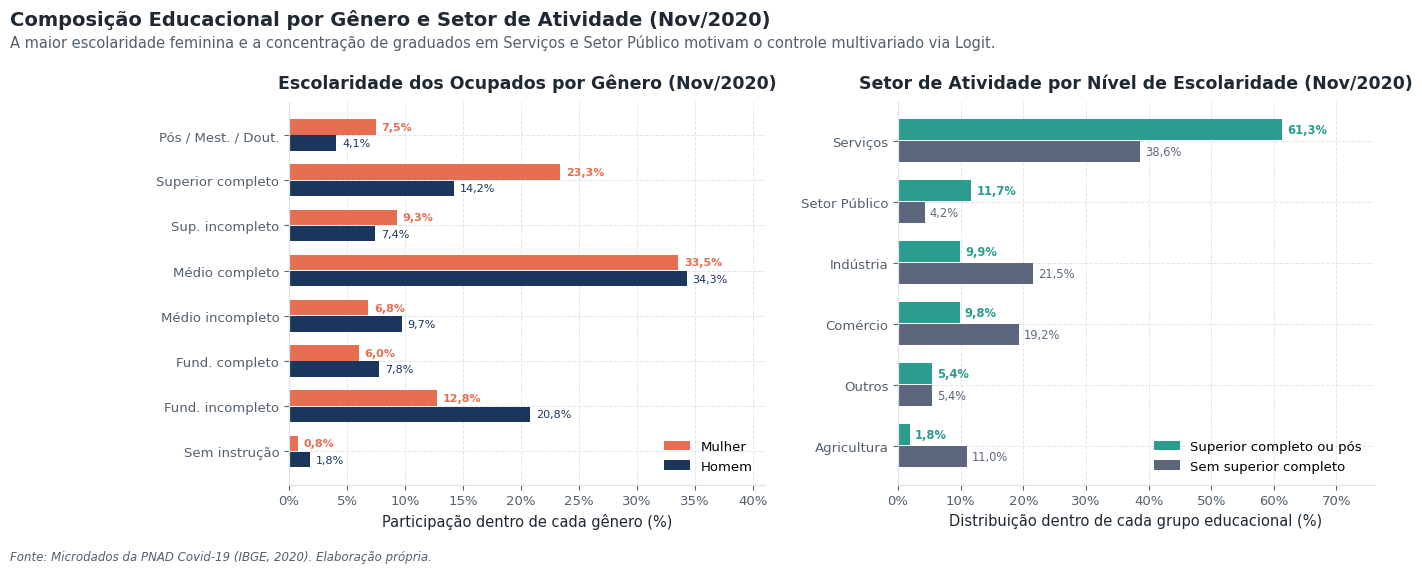

In [7]:
ocup_nov = ocup[ocup["mes"] == 11].copy()

gen_esc_nov = weighted_table(ocup_nov, "escolaridade", "genero", normalize="columns").reindex(ESCOLARIDADE_ORDER)
setor_sup_nov = weighted_table(
    ocup_nov.dropna(subset=["setor"]),
    "setor",
    "ensino_superior",
    normalize="columns",
).reindex(SETOR_ORDER).rename(columns={0: "Sem superior completo", 1: "Superior completo ou pós"})

print("Distribuição educacional dos ocupados por gênero (%, nov/2020):")
display(gen_esc_nov.round(1))
print("\nDistribuição setorial segundo presença de ensino superior (%, nov/2020):")
display(setor_sup_nov.round(1))

# Figura 06: Escolaridade por gênero e setor por escolaridade
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.5, 5.8))
fig.subplots_adjust(top=0.80, bottom=0.14, left=0.20, wspace=0.28)

short_esc = {
    "Sem instrução": "Sem instrução",
    "Fundamental incompleto": "Fund. incompleto",
    "Fundamental completo": "Fund. completo",
    "Médio incompleto": "Médio incompleto",
    "Médio completo": "Médio completo",
    "Superior incompleto": "Sup. incompleto",
    "Superior completo": "Superior completo",
    "Pós-graduação, mestrado ou doutorado": "Pós / Mest. / Dout.",
}
y_e = np.arange(len(ESCOLARIDADE_ORDER))
ax1.barh(y_e + 0.18, gen_esc_nov["Mulher"], height=0.34, color=PALETTE["coral"], label="Mulher")
ax1.barh(y_e - 0.18, gen_esc_nov["Homem"], height=0.34, color=PALETTE["navy"], label="Homem")
for yi, c in enumerate(ESCOLARIDADE_ORDER):
    vm, vh = gen_esc_nov.loc[c, "Mulher"], gen_esc_nov.loc[c, "Homem"]
    ax1.text(vm + 0.5, yi + 0.18, f"{format_ptbr_number(vm, 1)}%", va="center", fontsize=8.0, color=PALETTE["coral"], fontweight="bold")
    ax1.text(vh + 0.5, yi - 0.18, f"{format_ptbr_number(vh, 1)}%", va="center", fontsize=8.0, color=PALETTE["navy"])
ax1.set_yticks(y_e)
ax1.set_yticklabels([short_esc[c] for c in ESCOLARIDADE_ORDER])
ax1.set_xlim(0, 41)
style_percent_axis(ax1, axis="x")
ax1.set_title("Escolaridade dos Ocupados por Gênero (Nov/2020)", pad=10)
ax1.set_xlabel("Participação dentro de cada gênero (%)")
ax1.legend(loc="lower right")

setor_plot_ord = setor_sup_nov.sort_values("Superior completo ou pós", ascending=True).index.tolist()
y_s = np.arange(len(setor_plot_ord))
ax2.barh(y_s + 0.18, setor_sup_nov.loc[setor_plot_ord, "Superior completo ou pós"], height=0.34,
         color=PALETTE["teal"], label="Superior completo ou pós")
ax2.barh(y_s - 0.18, setor_sup_nov.loc[setor_plot_ord, "Sem superior completo"], height=0.34,
         color=PALETTE["slate"], label="Sem superior completo")
for yi, s in enumerate(setor_plot_ord):
    vs = setor_sup_nov.loc[s, "Superior completo ou pós"]
    vn = setor_sup_nov.loc[s, "Sem superior completo"]
    ax2.text(vs + 0.8, yi + 0.18, f"{format_ptbr_number(vs, 1)}%", va="center", fontsize=8.3, color=PALETTE["teal"], fontweight="bold")
    ax2.text(vn + 0.8, yi - 0.18, f"{format_ptbr_number(vn, 1)}%", va="center", fontsize=8.3, color=PALETTE["slate"])
ax2.set_yticks(y_s)
ax2.set_yticklabels(setor_plot_ord)
ax2.set_xlim(0, 76)
style_percent_axis(ax2, axis="x")
ax2.set_title("Setor de Atividade por Nível de Escolaridade (Nov/2020)", pad=10)
ax2.set_xlabel("Distribuição dentro de cada grupo educacional (%)")
ax2.legend(loc="lower right")

add_title_and_source(
    fig,
    "Composição Educacional por Gênero e Setor de Atividade (Nov/2020)",
    "A maior escolaridade feminina e a concentração de graduados em Serviços e Setor Público motivam o controle multivariado via Logit.",
    title_y=0.96,
    subtitle_y=0.895,
    source_y=0.01,
)
save_figure(fig, "06_escolaridade_por_genero_e_setor.png")
plt.show()
